Volatility Breakout (Phá vỡ biến động) sử dụng lệnh chờ (Pending Orders).

Setup Long: Dải trên (Upper Band) của Keltner Channel đang giảm xuống.
KC_Upper(hiện tại) < KC_Upper(cây nến trước)

Setup Short: Dải dưới (Lower Band) của Keltner Channel đang tăng lên.
KC_Lower(hiện tại) > KC_Lower(cây nến trước)

1. Entry:

Lệnh Mua (Buy Stop):

Điều kiện: Có tín hiệu Setup Long (Upper Band đang co lại).
Giá đặt lệnh (Entry Price): Tenkan-Sen + (0.8 * ATR(40))
Hủy lệnh (Expiration): Lệnh chờ sẽ tự hủy sau 6 cây nến nếu không khớp.

Lệnh Bán (Sell Stop):

Điều kiện: Có tín hiệu Setup Short (Lower Band đang co lại) VÀ không có tín hiệu Long.
Giá đặt lệnh (Entry Price): Tenkan-Sen - (0.8 * ATR(40))

Expiration: 6 cây nến.

2. Exit & Management:

Chiến lược không sử dụng tín hiệu đảo chiều từ chỉ báo để thoát lệnh (biến LongExitSignal và ShortExitSignal được set cứng là false). Việc thoát lệnh hoàn toàn dựa trên quản lý vốn và thời gian:

Stop Loss (Cắt lỗ): Dựa trên biến động: 2.0 * ATR(20) (Tính từ giá vào lệnh).
Profit Target (Chốt lời): 3.6 * ATR(20). Tỷ lệ R:R (Risk/Reward) là 1:1.8.
Trailing Stop (Dời lỗ): 1.5 * ATR(90).

Exit After X Bars: Bắt buộc đóng lệnh sau 40 cây nến (khoảng gần 2 ngày trên khung H1) bất kể lời lỗ nếu chưa chạm SL/PT.

3. Money Management

Rủi ro: Cố định 1.0% tài khoản cho mỗi lệnh (mmRiskPercent = 1.0).
Khối lượng: Được tính toán tự động dựa trên khoảng cách Stop Loss để đảm bảo chỉ mất 1% nếu dính SL.




📡 Đang kiểm tra kết nối tới Binance...
⏳ Bắt đầu tải BTCUSDT khung 1h từ https://data-api.binance.vision/...
   -> Đã tải đến: 15/03/2018 (5000 nến)
   -> Đã tải đến: 10/10/2018 (10000 nến)
   -> Đã tải đến: 07/05/2019 (15000 nến)
   -> Đã tải đến: 02/12/2019 (20000 nến)
   -> Đã tải đến: 28/06/2020 (25000 nến)
   -> Đã tải đến: 22/01/2021 (30000 nến)
   -> Đã tải đến: 19/08/2021 (35000 nến)
   -> Đã tải đến: 16/03/2022 (40000 nến)
   -> Đã tải đến: 10/10/2022 (45000 nến)
   -> Đã tải đến: 06/05/2023 (50000 nến)
   -> Đã tải đến: 01/12/2023 (55000 nến)
   -> Đã tải đến: 26/06/2024 (60000 nến)
   -> Đã tải đến: 20/01/2025 (65000 nến)
   -> Đã tải đến: 17/08/2025 (70000 nến)
✅ Tải hoàn tất! Tổng cộng: 73284 cây nến.
⚙️ Đang chạy Backtest Strategy 2.5.115...

📊 KẾT QUẢ BACKTEST: BTCUSDT
Vốn đầu tư:     $10,000
Vốn cuối cùng:  $1,169.51
Lợi nhuận ròng: -88.30%
Max Drawdown:   -95.99%
Tổng số lệnh:   3438
Tỉ lệ thắng:    34.96%


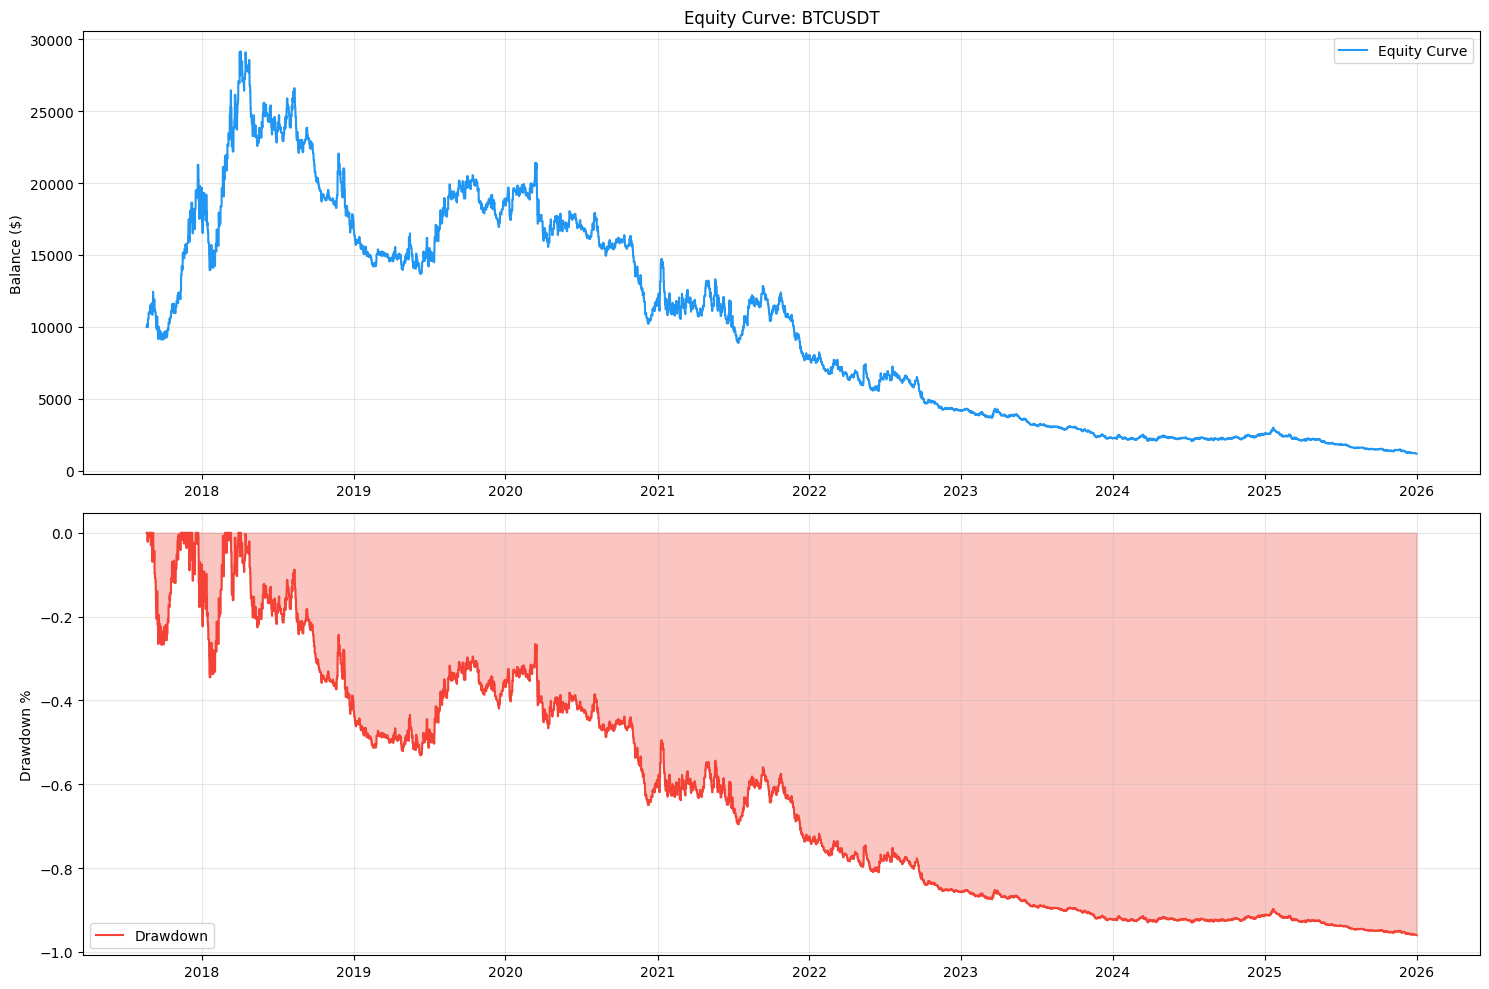

In [14]:
# ==============================================================================
# BƯỚC 1: CÀI ĐẶT THƯ VIỆN
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# BƯỚC 2: CẤU HÌNH CHIẾN LƯỢC (Strategy 2.5.115)
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1h',
    'START_DATE': '01/01/2015',  # Định dạng dd/mm/yyyy
    'END_DATE': '31/12/2025',
    'INITIAL_CAPITAL': 10000.0,

    # --- Indicators ---
    'KC_PERIOD': 20,
    'KC_MULT': 2.3,
    'TENKAN_PERIOD': 87,
    'ATR_ENTRY_PERIOD': 40,
    'ATR_SL_PT_PERIOD': 20,
    'ATR_TRAIL_PERIOD': 90,

    # Entry & Management
    'ENTRY_BUFFER_ATR': 0.8,
    'SL_ATR_MULT': 2.0,
    'PT_ATR_MULT': 3.6,
    'TRAIL_ATR_MULT': 1.5,
    'ORDER_EXPIRATION': 6,
    'TIME_EXIT_BARS': 40,

    # Costs
    'FEE_RATE': 0.0004,       # 0.04%
    'SLIPPAGE': 0.0002        # 0.02%
}

# ==============================================================================
# BƯỚC 3: MODULE TẢI DỮ LIỆU (Code của bạn + Fix IP Mỹ)
# ==============================================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    # 1. Cấu hình URL
    # Mặc định dùng Binance Quốc tế

    base_url = "https://data-api.binance.vision/"
    url = base_url + "api/v3/klines"
    req_symbol = symbol.upper()

    # 2. Kiểm tra kết nối thử để xem có bị chặn IP không
    print("📡 Đang kiểm tra kết nối tới Binance...")
    try:
        test = requests.get(f"{base_url}/api/v3/time", timeout=5)
        if test.status_code == 451: # Lỗi chặn IP Mỹ
            print("⚠️ Phát hiện IP Mỹ (Google Colab). Chuyển sang Binance.US...")
            base_url = "https://api.binance.us"
            # Binance US dùng cặp BTCUSD thay vì BTCUSDT (thường là vậy)
            if req_symbol == "BTCUSDT":
                req_symbol = "BTCUSD"
                print(f"🔄 Đổi symbol thành {req_symbol} để hợp lệ với Binance.US")
    except:
        print("⚠️ Kết nối Binance QT thất bại. Thử Binance.US...")
        base_url = "https://api.binance.us"
        req_symbol = "BTCUSD"

    url = base_url + "/api/v3/klines"

    # 3. Chuẩn bị thời gian
    start_time = str_to_millis(start_str)

    # Xử lý ngày kết thúc hiện tại
    if end_str == datetime.now().strftime("%d/%m/%Y"):
        end_time = int(time.time() * 1000)
    else:
        end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
        end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Bắt đầu tải {req_symbol} khung {interval} từ {base_url}...")

    # 4. Vòng lặp tải dữ liệu
    while start_time < end_time:
        params = {
            "symbol": req_symbol,
            "interval": interval,
            "startTime": start_time,
            "endTime": end_time,
            "limit": 1000
        }
        try:
            r = requests.get(url, params=params, timeout=10)

            if r.status_code != 200:
                print(f"❌ Lỗi Fetch ({r.status_code}): {r.text}")
                break

            data = r.json()
            if not data:
                break

            all_klines.extend(data)
            start_time = data[-1][0] + 1 # Cập nhật thời gian bắt đầu cho lần sau

            # In tiến trình mỗi 5000 nến
            if len(all_klines) % 5000 == 0:
                curr_date = datetime.fromtimestamp(data[-1][0]/1000).strftime('%d/%m/%Y')
                print(f"   -> Đã tải đến: {curr_date} ({len(all_klines)} nến)")

            time.sleep(0.05) # Nghỉ nhẹ tránh limit

        except Exception as e:
            print("❌ Lỗi ngoại lệ:", e)
            break

    if not all_klines:
        print("⚠️ Không tải được dữ liệu nào! (Kiểm tra lại Symbol hoặc IP)")
        return pd.DataFrame()

    # 5. Xử lý DataFrame
    df = pd.DataFrame(all_klines, columns=[
        "timestamp", "Open", "High", "Low", "Close", "Volume",
        "close_time", "quote_asset_volume", "num_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore"
    ])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)

    print(f"✅ Tải hoàn tất! Tổng cộng: {len(df)} cây nến.")
    return df

# ==============================================================================
# BƯỚC 4: BACKTEST ENGINE
# ==============================================================================
def run_strategy(df):
    print("⚙️ Đang chạy Backtest Strategy 2.5.115...")
    df = df.copy()
    c = CONFIG

    # --- A. INDICATORS ---
    # ATRs
    df['ATR_Entry'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_ENTRY_PERIOD'])
    df['ATR_SLPT']  = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_SL_PT_PERIOD'])
    df['ATR_Trail'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_TRAIL_PERIOD'])

    # Tenkan-Sen (High + Low) / 2
    df['Tenkan'] = (df['High'].rolling(c['TENKAN_PERIOD']).max() + df['Low'].rolling(c['TENKAN_PERIOD']).min()) / 2

    # Keltner Channels
    kc_basis = ta.ema(df['Close'], length=c['KC_PERIOD'])
    kc_range = ta.atr(df['High'], df['Low'], df['Close'], length=c['KC_PERIOD'])
    df['KC_Upper'] = kc_basis + (c['KC_MULT'] * kc_range)
    df['KC_Lower'] = kc_basis - (c['KC_MULT'] * kc_range)

    df.dropna(inplace=True)

    # --- B. VARIABLES ---
    capital = c['INITIAL_CAPITAL']
    position = 0          # 0: Cash, 1: Long, -1: Short
    entry_price = 0.0
    entry_idx = 0
    sl_price = 0.0
    tp_price = 0.0

    pending_orders = []
    trades = []
    equity_curve = [c['INITIAL_CAPITAL']] * len(df)

    # Numpy Arrays
    opens = df['Open'].values; highs = df['High'].values; lows = df['Low'].values; closes = df['Close'].values
    times = df.index

    atr_entry = df['ATR_Entry'].values; atr_slpt = df['ATR_SLPT'].values; atr_trail = df['ATR_Trail'].values
    tenkan = df['Tenkan'].values
    kc_upper = df['KC_Upper'].values; kc_lower = df['KC_Lower'].values

    # --- C. MAIN LOOP ---
    for i in range(1, len(df)):

        # 1. QUẢN LÝ LỆNH ĐANG MỞ (EXIT)
        if position != 0:
            exit_signal = False; exit_reason = ""; raw_exit_price = closes[i]

            # Kiểm tra SL/TP
            if position == 1:
                if lows[i] <= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif highs[i] >= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            elif position == -1:
                if highs[i] >= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif lows[i] <= tp_price:
                    exit_signal = True; exit_reason = "TP Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            if exit_signal:
                if position == 1:
                    real_exit = min(opens[i], raw_exit_price) if exit_reason == "SL Hit" else raw_exit_price
                    real_exit *= (1 - c['SLIPPAGE'])
                    pnl = (real_exit - entry_price) / entry_price
                else:
                    real_exit = max(opens[i], raw_exit_price) if exit_reason == "SL Hit" else raw_exit_price
                    real_exit *= (1 + c['SLIPPAGE'])
                    pnl = (entry_price - real_exit) / entry_price

                net_pnl = pnl - (c['FEE_RATE'] * 2)
                pnl_amt = capital * net_pnl
                capital += pnl_amt

                trades.append({
                    'Date': times[i], 'Type': 'Long' if position == 1 else 'Short',
                    'Reason': exit_reason, 'Entry': entry_price, 'Exit': real_exit,
                    'PnL': pnl_amt, 'Equity': capital
                })
                position = 0; pending_orders = []

            else:
                # Trailing Stop
                if position == 1:
                    new_sl = closes[i] - (c['TRAIL_ATR_MULT'] * atr_trail[i])
                    if new_sl > sl_price: sl_price = new_sl
                elif position == -1:
                    new_sl = closes[i] + (c['TRAIL_ATR_MULT'] * atr_trail[i])
                    if new_sl < sl_price: sl_price = new_sl

        # 2. XỬ LÝ KHỚP LỆNH CHỜ (ENTRY)
        if position == 0:
            pending_orders = [o for o in pending_orders if (i - o['created_idx']) < c['ORDER_EXPIRATION']]
            triggered = None
            for order in pending_orders:
                if order['type'] == 'buy' and highs[i] >= order['price']:
                    triggered = order; exec_price = max(opens[i], order['price']) if opens[i] > order['price'] else order['price']
                    break
                elif order['type'] == 'sell' and lows[i] <= order['price']:
                    triggered = order; exec_price = min(opens[i], order['price']) if opens[i] < order['price'] else order['price']
                    break

            if triggered:
                entry_idx = i
                if triggered['type'] == 'buy':
                    position = 1
                    entry_price = exec_price * (1 + c['SLIPPAGE'])
                    sl_price = exec_price - (c['SL_ATR_MULT'] * atr_slpt[i])
                    tp_price = exec_price + (c['PT_ATR_MULT'] * atr_slpt[i])
                else:
                    position = -1
                    entry_price = exec_price * (1 - c['SLIPPAGE'])
                    sl_price = exec_price + (c['SL_ATR_MULT'] * atr_slpt[i])
                    tp_price = exec_price - (c['PT_ATR_MULT'] * atr_slpt[i])
                pending_orders = []

        # 3. TẠO TÍN HIỆU MỚI (Logic Squeeze 2.5.115)
        if position == 0:
            # Logic: Upper Band đi xuống (Nén)
            long_cond = kc_upper[i] < kc_upper[i-1]
            # Logic: Lower Band đi lên (Nén)
            short_cond = kc_lower[i] > kc_lower[i-1]

            buffer = c['ENTRY_BUFFER_ATR'] * atr_entry[i]

            if long_cond:
                pending_orders.append({'type': 'buy', 'price': tenkan[i] + buffer, 'created_idx': i})

            if short_cond and not long_cond:
                pending_orders.append({'type': 'sell', 'price': tenkan[i] - buffer, 'created_idx': i})

        equity_curve[i] = capital

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trades)

# ==============================================================================
# BƯỚC 5: CHẠY VÀ VISUALIZE
# ==============================================================================
if __name__ == "__main__":
    # 1. Tải Data (Sử dụng code của bạn)
    df = fetch_binance_kline_df(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])

    if not df.empty:
        # 2. Run Strategy
        equity, trades_df = run_strategy(df)

        # 3. Kết quả
        if not trades_df.empty:
            final_equity = equity.iloc[-1]
            profit = final_equity - CONFIG['INITIAL_CAPITAL']
            ret_pct = (profit / CONFIG['INITIAL_CAPITAL']) * 100

            rolling_max = equity.cummax()
            dd = (equity - rolling_max) / rolling_max
            max_dd = dd.min() * 100

            win_trades = trades_df[trades_df['PnL'] > 0]
            winrate = len(win_trades) / len(trades_df) * 100

            print(f"\n{'='*40}")
            print(f"📊 KẾT QUẢ BACKTEST: {CONFIG['SYMBOL']}")
            print(f"{'='*40}")
            print(f"Vốn đầu tư:     ${CONFIG['INITIAL_CAPITAL']:,.0f}")
            print(f"Vốn cuối cùng:  ${final_equity:,.2f}")
            print(f"Lợi nhuận ròng: {ret_pct:.2f}%")
            print(f"Max Drawdown:   {max_dd:.2f}%")
            print(f"Tổng số lệnh:   {len(trades_df)}")
            print(f"Tỉ lệ thắng:    {winrate:.2f}%")

            # Plot
            plt.figure(figsize=(15, 10))

            plt.subplot(2, 1, 1)
            plt.plot(equity, label='Equity Curve', color='#2196F3')
            plt.title(f'Equity Curve: {CONFIG["SYMBOL"]}')
            plt.ylabel('Balance ($)')
            plt.grid(True, alpha=0.3)
            plt.legend()

            plt.subplot(2, 1, 2)
            plt.fill_between(dd.index, dd, 0, color='#F44336', alpha=0.3)
            plt.plot(dd, label='Drawdown', color='#F44336')
            plt.ylabel('Drawdown %')
            plt.grid(True, alpha=0.3)
            plt.legend()

            plt.tight_layout()
            plt.show()
        else:
            print("⚠️ Không có lệnh nào được khớp!")
    else:
        print("❌ Không có dữ liệu.")